# Лабораторная работа 9

Для выполнения лабораторной работы был выбран датасет Satellite Image Classification (https://www.kaggle.com/datasets/mahmoudreda55/satellite-image-classification?resource=download)

Датасет содержит 4 различных класса спутниковых снимков: cloudy, desert, green_area, water.

Загрузка изображений и вывода нескольких из них:

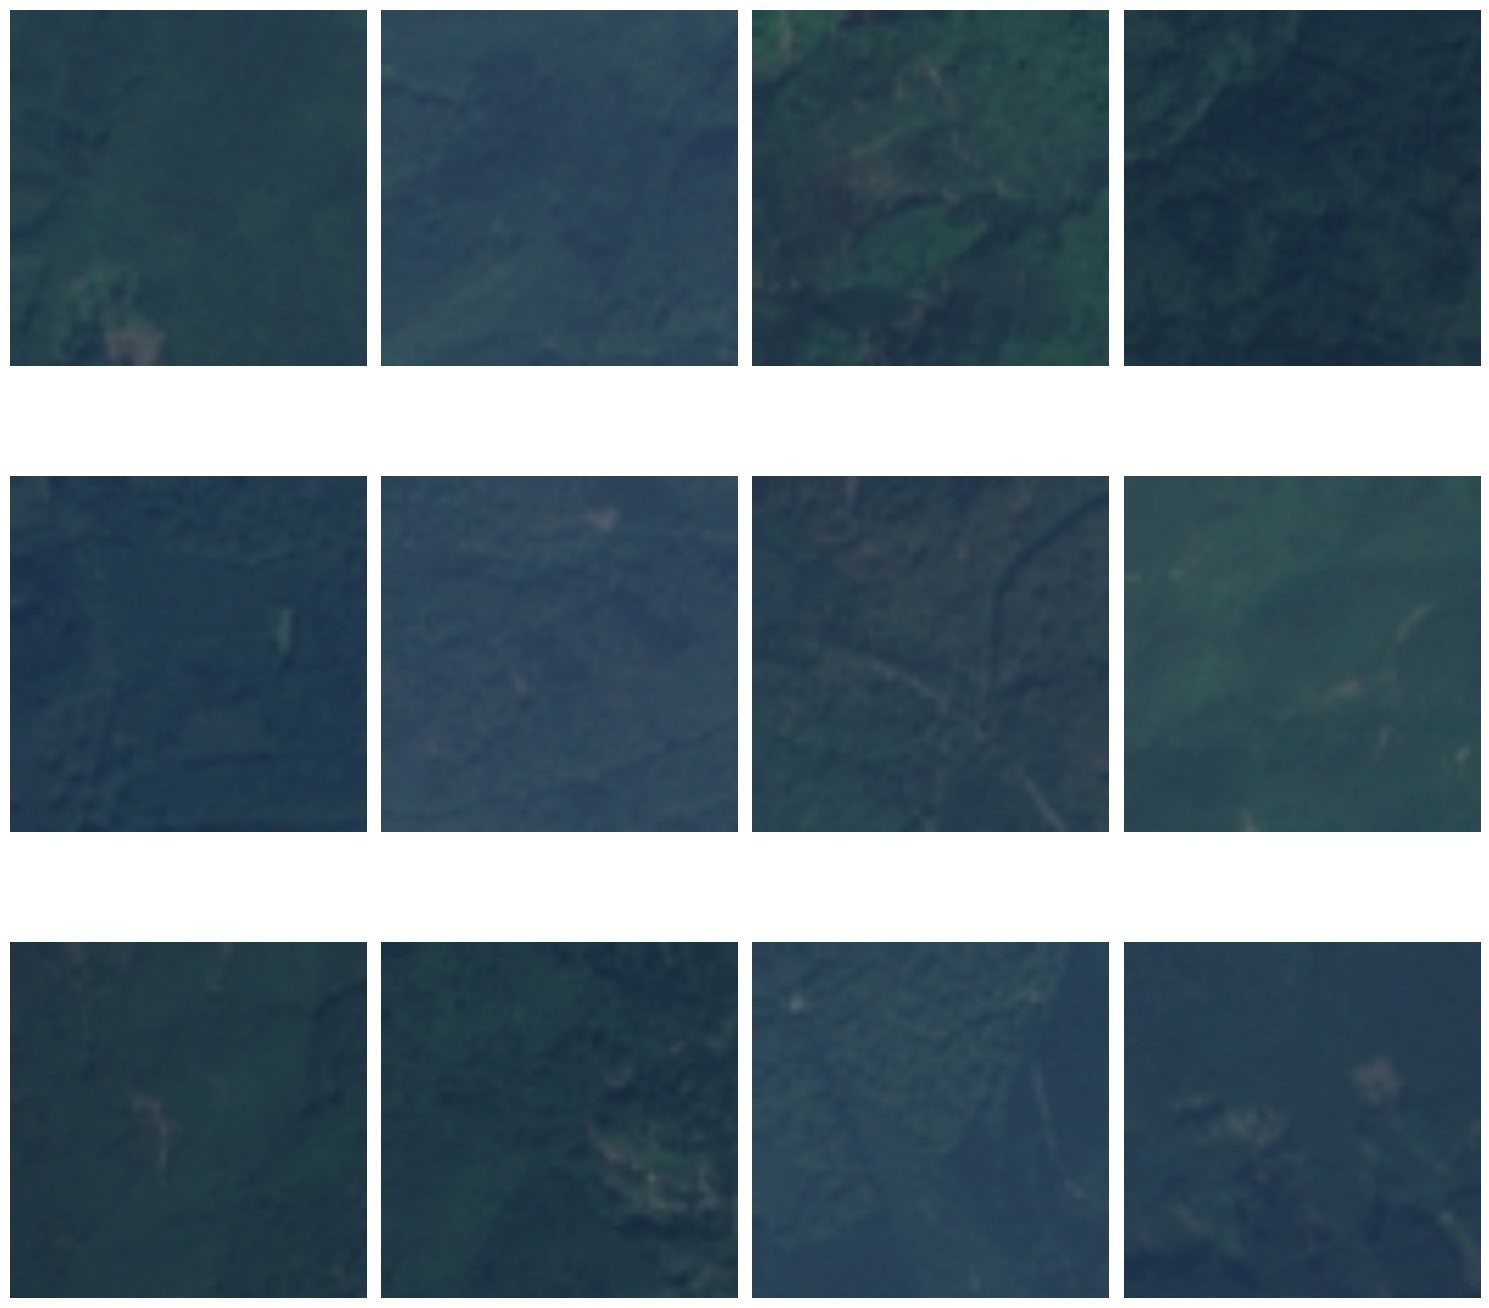

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_images_from_folder(folder, folders_order=None, target_size=(512, 512)):
    images = []
    labels = []
    if folders_order is None:
        folders_order = [d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d))]

    for label in folders_order:
        label_folder = os.path.join(folder, label)
        if os.path.isdir(label_folder):
            for filename in os.listdir(label_folder):
                img_path = os.path.join(label_folder, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    img_resized = cv2.resize(img, target_size)
                    images.append(img_resized)
                    labels.append(label)

    return images, labels

folder_path = "../data/images"
order = ['green_area', 'cloudy', 'desert', 'water']
images, labels = load_images_from_folder(folder_path, order)
num_images_to_display = min(12, len(images))

if images:
    cols = 4  
    rows = num_images_to_display // cols + (num_images_to_display % cols > 0)  
    plt.figure(figsize=(15, 5 * rows))
    for i in range(num_images_to_display):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.axis('off')
    plt.tight_layout()
    plt.show()

images = np.array(images)  
labels = np.array(labels)

Подготовка изображений к последующему анализу, применив методы предообработки изображений

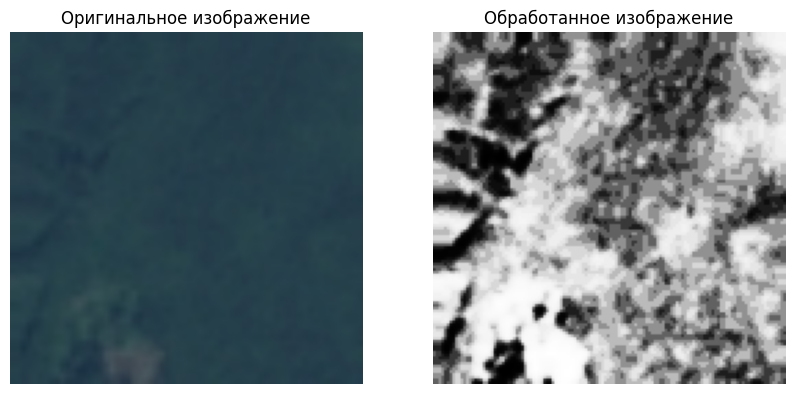

In [2]:
def preprocess_images(images):
    processed_images = []
    for img in images:
        # Изменение размера
        img_resized = cv2.resize(img, (128, 128))
        # Преобразование в оттенки серого
        img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
        # Увеличение контраста с помощью выравнивания гистограммы
        img_eq = cv2.equalizeHist(img_gray)
        processed_images.append(img_eq)
    return np.array(processed_images)

processed_images = preprocess_images(images)

def display_single_image(original, processed, index):
    plt.figure(figsize=(10, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original[index], cv2.COLOR_BGR2RGB))
    plt.title('Оригинальное изображение')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(processed[index], cmap='gray')
    plt.title('Обработанное изображение')
    plt.axis('off')

    plt.show()
 
display_single_image(images, processed_images, 0)

Проверяем работу методов фильтрации и восстановления изображений

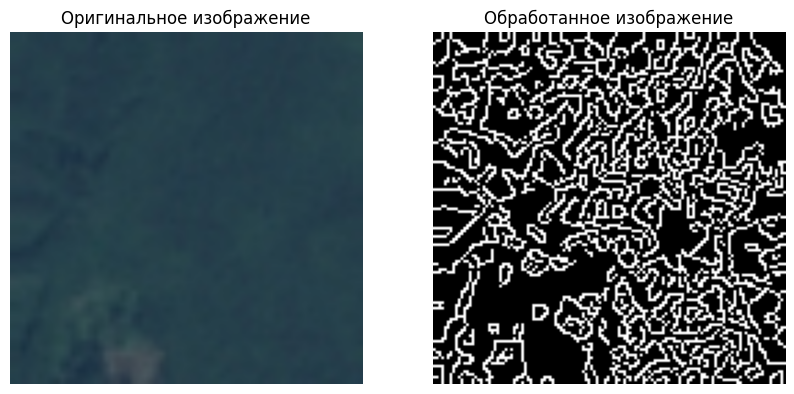

In [3]:
def apply_filters(img):
    # Удаление шумов
    img_blur = cv2.GaussianBlur(img, (5, 5), 0)
    # Повышение резкости
    kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    img_sharp = cv2.filter2D(img_blur, -1, kernel)
    # Определение границ
    img_edges = cv2.Canny(img_sharp, 100, 200)
    return img_edges

filtered_images = np.array([apply_filters(img) for img in processed_images])

display_single_image(images, filtered_images, 0)

Извлечение признаков:

In [4]:
import mahotas

def extract_color_features(img):
    color_features = []
    if len(img.shape) == 2:
        mean = np.mean(img)
        stddev = np.std(img)
        hist = cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()
        color_features.extend([mean, stddev])
        color_features.extend(hist)
    else:
        for i in range(3):
            channel = img[:, :, i]
            mean = np.mean(channel)
            stddev = np.std(channel)
            hist = cv2.calcHist([channel], [0], None, [256], [0, 256]).flatten()
            color_features.extend([mean, stddev])
            color_features.extend(hist)
    return np.array(color_features)

def extract_texture_features(img):
    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    haralick_features = mahotas.features.haralick(img).mean(axis=0)
    return haralick_features

def extract_features(images):
    features = []
    for img in images:
        color_features = extract_color_features(img)
        texture_features = extract_texture_features(img)
        combined_features = np.hstack([color_features, texture_features])
        features.append(combined_features)
    return np.array(features)

features_array = extract_features(filtered_images)
labels_array = np.array(labels)

Обучаем модель:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

def train_and_evaluate_svm(features_array, labels_array, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(
        features_array, labels_array, test_size=test_size, random_state=random_state
    )
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    model = SVC(kernel='linear')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("Classification Report")
    print(classification_report(y_test, y_pred))

train_and_evaluate_svm(features_array, labels_array)

 Classification Report
              precision    recall  f1-score   support

      cloudy       0.81      0.35      0.49       298
      desert       0.64      0.78      0.70       213
  green_area       0.84      0.93      0.88       328
       water       0.59      0.77      0.67       288

    accuracy                           0.71      1127
   macro avg       0.72      0.71      0.68      1127
weighted avg       0.73      0.71      0.69      1127



Попробуем решить задачу аугментации для 10 случайных изображений из каждого класса датасета

In [6]:
from collections import defaultdict
import random
import albumentations as A

def augment_image(image):
    transform = A.Compose([
        A.HorizontalFlip(p=0.5),  
        A.VerticalFlip(p=0.5),    
        A.RandomRotate90(p=0.5),
        A.Affine(scale=(0.9, 1.1), translate_percent=(0.1, 0.1), rotate=(-30, 30), p=0.5), 
        A.RandomBrightnessContrast(p=0.2),  
        A.GaussianBlur(p=0.1),  
        A.RGBShift(p=0.2),  
        A.CLAHE(p=0.1),  
        A.RandomGamma(p=0.1),  
        A.HueSaturationValue(p=0.2),  
    ])
    return transform(image=image)['image']

class_to_images = defaultdict(list)
for img, label in zip(images, labels):
    class_to_images[label].append(img)

augmented_images = []
augmented_labels = []

for label in order:
    original_imgs = class_to_images[label]
    selected = random.sample(original_imgs, min(10, len(original_imgs)))
    for img in selected:
        for _ in range(10):
            aug_img = augment_image(img)
            augmented_images.append(aug_img)
            augmented_labels.append(label)

images = np.concatenate([images, np.array(augmented_images)], axis=0)
labels = np.concatenate([labels, np.array(augmented_labels)], axis=0)

Оценим качество модели на полученном в итоге наборе данных:

In [7]:
processed_images = preprocess_images(images)
filtered_images = np.array([apply_filters(img) for img in processed_images])
features_array = extract_features(filtered_images)
labels_array = np.array(labels)
train_and_evaluate_svm(features_array, labels_array)

Classification Report
              precision    recall  f1-score   support

      cloudy       0.79      0.35      0.48       317
      desert       0.63      0.74      0.68       238
  green_area       0.85      0.94      0.89       345
       water       0.59      0.78      0.67       307

    accuracy                           0.70      1207
   macro avg       0.71      0.70      0.68      1207
weighted avg       0.72      0.70      0.68      1207



Аугментация данных в таком ограниченном объеме не оказала значительного влияния на результаты обучения модели.